In [33]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib



In [34]:
df = pd.read_csv("insurance.csv")

df.head()


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [35]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [36]:

df.describe()


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [37]:
df.shape

(1338, 7)

In [38]:
#EDA


df.isnull().sum()


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [39]:

df.duplicated().sum()


np.int64(1)

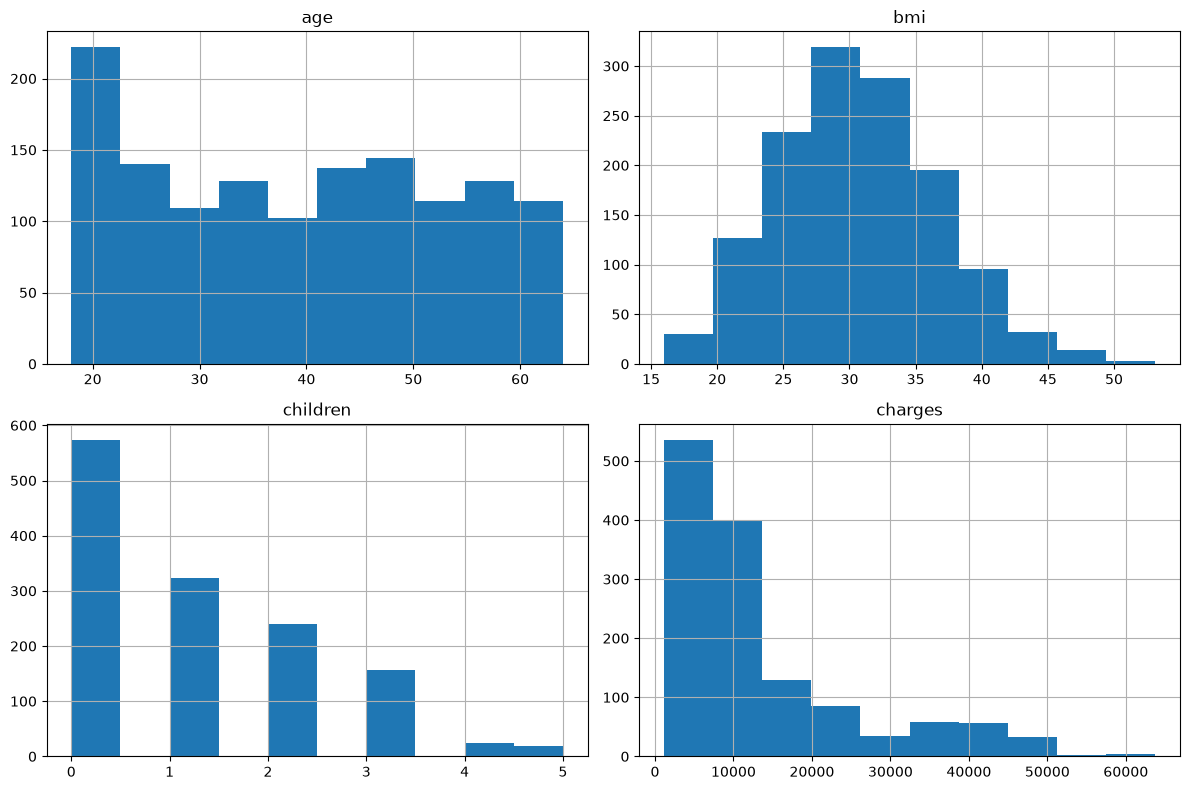

In [40]:

df.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()


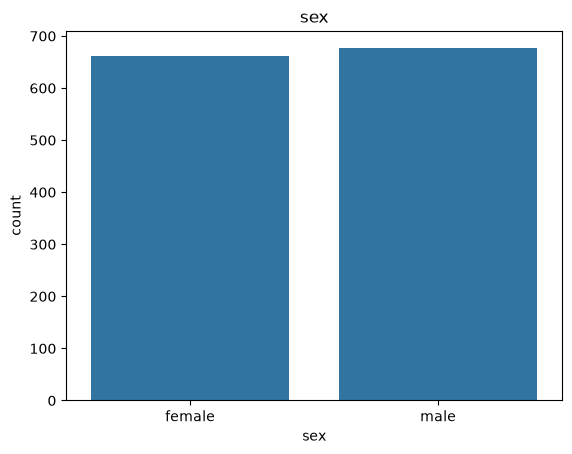

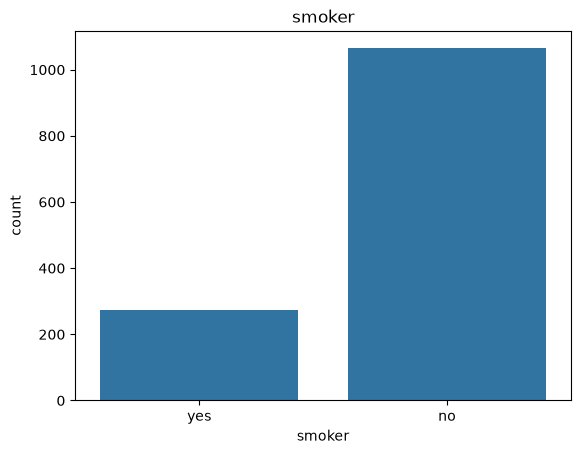

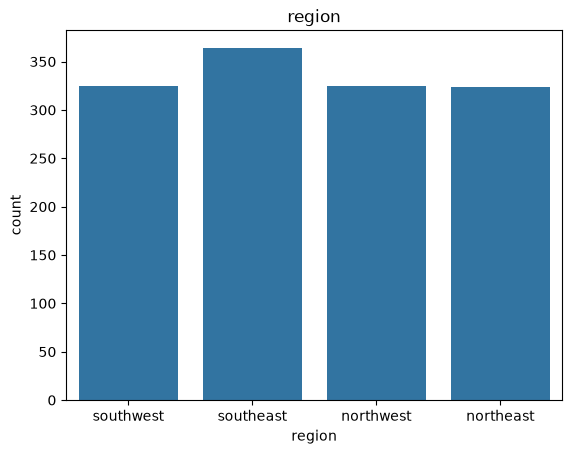

In [41]:

for col in ["sex", "smoker", "region"]:
    sns.countplot(x=col, data=df)
    plt.title(col)
    plt.show()


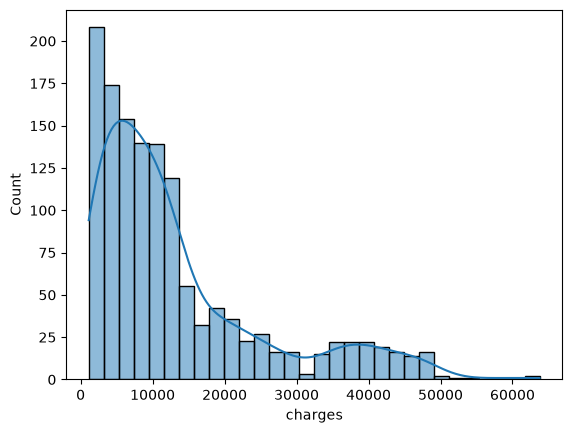

In [42]:

sns.histplot(df["charges"], kde=True)
plt.show()


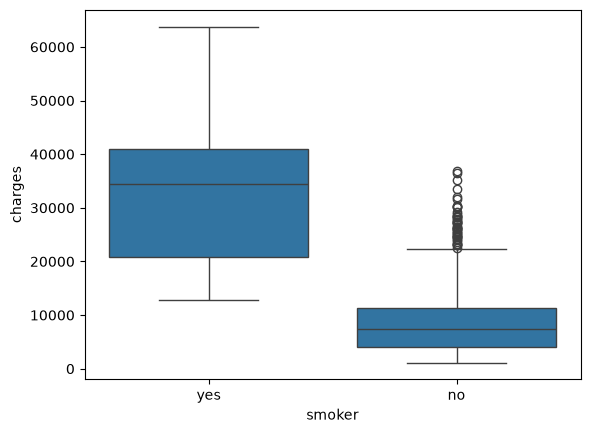

In [43]:

sns.boxplot(x="smoker", y="charges", data=df)
plt.show()


In [44]:

for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna(df[col].mode()[0])


/var/folders/r2/_4dp66rx45b98x_cnlz27j0h0000gn/T/ipykernel_10275/3065003742.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


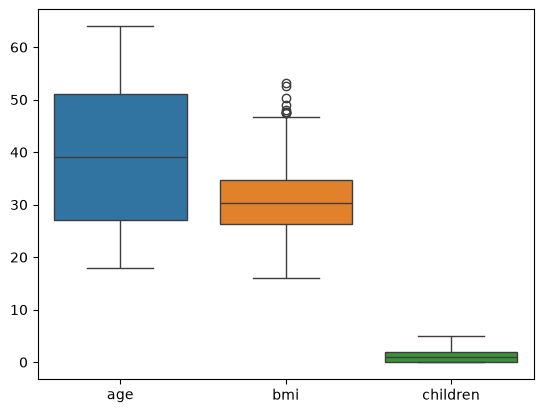

In [45]:

sns.boxplot(data=df[["age", "bmi", "children"]])
plt.show()


In [46]:

df.select_dtypes(include="number").skew()


age         0.055673
bmi         0.284047
children    0.938380
charges     1.515880
dtype: float64

In [47]:
df.corr(numeric_only=True)

,age,bmi,children,charges
age,1.000000,0.109272,0.042469,0.299008
bmi,0.109272,1.000000,0.012759,0.198341
children,0.042469,0.012759,1.000000,0.067998
charges,0.299008,0.198341,0.067998,1.000000


In [48]:
df1 = pd.get_dummies(df, drop_first=True, dtype=int)

df1.corr()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
age,1.000000,0.109272,0.042469,0.299008,-0.020856,-0.025019,-0.000407,-0.011642,0.010016
bmi,0.109272,1.000000,0.012759,0.198341,0.046371,0.003750,-0.135996,0.270025,-0.006205
children,0.042469,0.012759,1.000000,0.067998,0.017163,0.007673,0.024806,-0.023066,0.021914
charges,0.299008,0.198341,0.067998,1.000000,0.057292,0.787251,-0.039905,0.073982,-0.043210
sex_male,-0.020856,0.046371,0.017163,0.057292,1.000000,0.076185,-0.011156,0.017117,-0.004184
smoker_yes,-0.025019,0.003750,0.007673,0.787251,0.076185,1.000000,-0.036945,0.068498,-0.036945
region_northwest,-0.000407,-0.135996,0.024806,-0.039905,-0.011156,-0.036945,1.000000,-0.346265,-0.320829
region_southeast,-0.011642,0.270025,-0.023066,0.073982,0.017117,0.068498,-0.346265,1.000000,-0.346265
region_southwest,0.010016,-0.006205,0.021914,-0.043210,-0.004184,-0.036945,-0.320829,-0.346265,1.000000


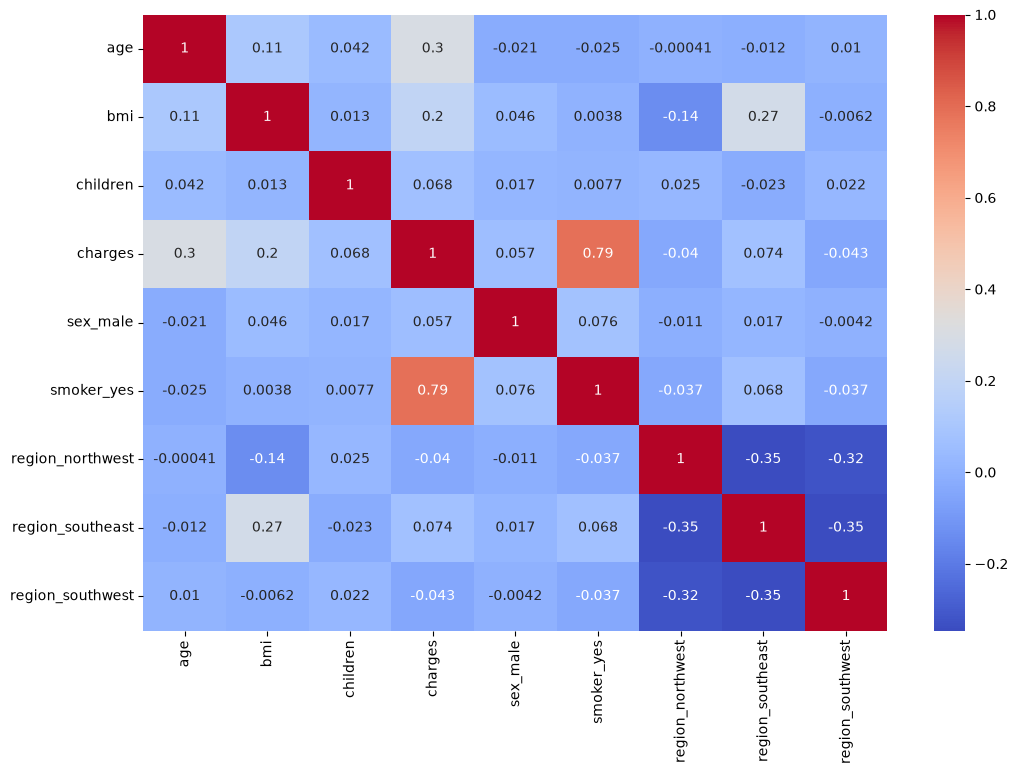

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.heatmap(df1.corr(), annot=True, cmap="coolwarm")

plt.show()

In [50]:
df1.corr()["charges"].sort_values(ascending=False)

charges             1.000000
smoker_yes          0.787251
age                 0.299008
bmi                 0.198341
region_southeast    0.073982
children            0.067998
sex_male            0.057292
region_northwest   -0.039905
region_southwest   -0.043210
Name: charges, dtype: float64

In [51]:

df1 = pd.get_dummies(df, columns=["sex", "smoker", "region"], dtype=int)

df1.head()


,age,bmi,children,charges,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,1,0,0,1,0,0,0,1
1,18,33.770,1,1725.55230,0,1,1,0,0,0,1,0
2,28,33.000,3,4449.46200,0,1,1,0,0,0,1,0
3,33,22.705,0,21984.47061,0,1,1,0,0,1,0,0
4,32,28.880,0,3866.85520,0,1,1,0,0,1,0,0


In [52]:

X = df1.drop("charges", axis=1)
y = df1["charges"]


In [53]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [54]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [55]:

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, BaggingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "Bagging": BaggingRegressor(random_state=42),
    "SVR": SVR(),
    "KNN": KNeighborsRegressor()
}


In [56]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_mae = mean_absolute_error(y_train, train_pred)
    test_mae = mean_absolute_error(y_test, test_pred)

    train_mse = mean_squared_error(y_train, train_pred)
    test_mse = mean_squared_error(y_test, test_pred)

    train_rmse = np.sqrt(train_mse)
    test_rmse = np.sqrt(test_mse)

    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)

    p = X.shape[1]

    train_adj = 1 - (1 - train_r2) * (len(y_train) - 1) / (len(y_train) - p - 1)
    test_adj = 1 - (1 - test_r2) * (len(y_test) - 1) / (len(y_test) - p - 1)

    results.append([
        name, train_mae, test_mae,
        train_mse, test_mse,
        train_rmse, test_rmse,
        train_r2, test_r2,
        train_adj, test_adj,
        "Yes" if train_r2 - test_r2 > 0.1 else "No"
    ])


In [57]:

columns = [
    "Model", "Train MAE", "Test MAE",
    "Train MSE", "Test MSE",
    "Train RMSE", "Test RMSE",
    "Train R2", "Test R2",
    "Train Adjusted R2", "Test Adjusted R2",
    "Overfitting"
]

results_df = pd.DataFrame(results, columns=columns)

results_df.round(3)


,Model,Train MAE,Test MAE,Train MSE,Test MSE,Train RMSE,Test RMSE,Train R2,Test R2,Train Adjusted R2,Test Adjusted R2,Overfitting
0,Linear Regression,4208.235,4181.194,3.727768e+07,3.359692e+07,6105.545,5796.285,0.742,0.784,0.739,0.774,No
1,Decision Tree,29.573,3227.665,2.442396e+05,4.446327e+07,494.206,6668.078,0.998,0.714,0.998,0.701,Yes
2,Random Forest,1031.018,2549.152,3.605290e+06,2.102544e+07,1898.760,4585.351,0.975,0.865,0.975,0.859,Yes
3,Gradient Boosting,2096.939,2400.758,1.447224e+07,1.870194e+07,3804.240,4324.574,0.900,0.880,0.899,0.874,No
4,Bagging,1083.890,2583.865,5.079877e+06,2.355052e+07,2253.858,4852.887,0.965,0.848,0.964,0.842,Yes
5,SVR,8252.502,8611.416,1.578046e+08,1.659522e+08,12562.031,12882.244,-0.093,-0.069,-0.105,-0.115,No
6,KNN,2720.235,3540.861,2.025175e+07,3.117415e+07,4500.195,5583.381,0.860,0.799,0.858,0.791,No


In [58]:

results_df.sort_values("Test R2", ascending=False)


,Model,Train MAE,Test MAE,Train MSE,Test MSE,Train RMSE,Test RMSE,Train R2,Test R2,Train Adjusted R2,Test Adjusted R2,Overfitting
3,Gradient Boosting,2096.939347,2400.758193,1.447224e+07,1.870194e+07,3804.240225,4324.573905,0.899731,0.879536,0.898688,0.874359,No
2,Random Forest,1031.017981,2549.151667,3.605290e+06,2.102544e+07,1898.760166,4585.350888,0.975021,0.864569,0.974761,0.858750,Yes
4,Bagging,1083.889904,2583.865449,5.079877e+06,2.355052e+07,2253.858152,4852.887330,0.964805,0.848305,0.964439,0.841786,Yes
6,KNN,2720.234845,3540.860741,2.025175e+07,3.117415e+07,4500.194724,5583.381145,0.859688,0.799199,0.858229,0.790571,No
0,Linear Regression,4208.234572,4181.194474,3.727768e+07,3.359692e+07,6105.545160,5796.284659,0.741726,0.783593,0.739040,0.774294,No
1,Decision Tree,29.572515,3227.664954,2.442396e+05,4.446327e+07,494.205984,6668.078316,0.998308,0.713600,0.998290,0.701294,Yes
5,SVR,8252.502061,8611.415552,1.578046e+08,1.659522e+08,12562.030517,12882.243665,-0.093332,-0.068944,-0.104700,-0.114875,No


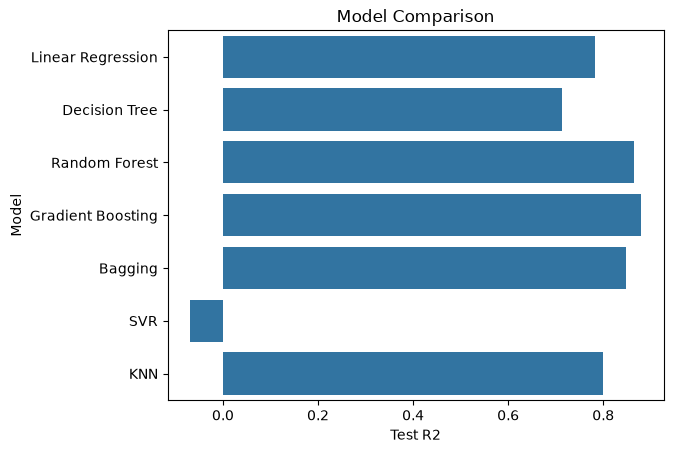

In [59]:

sns.barplot(data=results_df, x="Test R2", y="Model")
plt.title("Model Comparison")
plt.show()


In [60]:

from sklearn.model_selection import GridSearchCV

params = {
    "n_estimators": [50, 100],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 5]
}

grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    params,
    cv=5,
    scoring="r2"
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)


Best Parameters: {'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 50}


In [61]:

best_model = grid.best_estimator_

train_pred = best_model.predict(X_train)
test_pred = best_model.predict(X_test)

print("Train R2:", r2_score(y_train, train_pred))
print("Test R2:", r2_score(y_test, test_pred))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, test_pred)))


Train R2: 0.8864622450146704
Test R2: 0.8730618381987638
Test RMSE: 4439.255410261885


In [62]:

old_r2 = results_df.loc[
    results_df["Model"] == "Random Forest", "Test R2"
].iloc[0]

new_r2 = r2_score(y_test, test_pred)

print("Before Tuning:", old_r2)
print("After Tuning:", new_r2)
print("Improvement:", new_r2 - old_r2)


Before Tuning: 0.8645693104146611
After Tuning: 0.8730618381987638
Improvement: 0.0084925277841027


In [63]:
importance = pd.Series(
    best_model.feature_importances_,
    index=X.columns
)

print(importance.sort_values(ascending=False))

smoker_no           0.518397
bmi                 0.184449
smoker_yes          0.163169
age                 0.120319
children            0.009844
region_northeast    0.001670
region_northwest    0.000980
region_southwest    0.000410
sex_male            0.000325
region_southeast    0.000317
sex_female          0.000120
dtype: float64


In [64]:

joblib.dump(best_model, "best_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(X.columns.tolist(), "columns.pkl")

print("Files saved successfully!")


Files saved successfully!
